# Final Project: Video Game Sales 


link: https://www.kaggle.com/datasets/volodymyrpivoshenko/video-game-sales-dataset?resource=download

## Week 1

In [1]:
import pandas as pd


df = pd.read_csv("video_games_sales.csv")



print(df.head())
print(df.info())
print(df.describe())

print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

#Numerical: All Sales, Year
#Categorical: Name, Platform, Genre, Publisher



   Rank                      Name Platform    Year         Genre Publisher  \
0     1                Wii Sports      Wii  2006.0        Sports  Nintendo   
1     2         Super Mario Bros.      NES  1985.0      Platform  Nintendo   
2     3            Mario Kart Wii      Wii  2008.0        Racing  Nintendo   
3     4         Wii Sports Resort      Wii  2009.0        Sports  Nintendo   
4     5  Pokemon Red/Pokemon Blue       GB  1996.0  Role-Playing  Nintendo   

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
0     41.49     29.02      3.77         8.46         82.74  
1     29.08      3.58      6.81         0.77         40.24  
2     15.85     12.88      3.79         3.31         35.82  
3     15.75     11.01      3.28         2.96         33.00  
4     11.27      8.89     10.22         1.00         31.37  
<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        -----

In [2]:
print(df['Global_Sales'].quantile([0.5, 0.75, 0.9, 0.95]))

0.50    0.17
0.75    0.47
0.90    1.21
0.95    2.04
Name: Global_Sales, dtype: float64


In [3]:
# Fill missing Publisher
df['Publisher'] = df['Publisher'].fillna('Unknown')

# Drop rows with missing Year
df = df.dropna(subset=['Year'])

# Confirm changes
print(df.isnull().sum())
print("New shape:", df.shape)

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64
New shape: (16327, 11)


In [4]:
# Create hit vs non-hit (1 = hit, 0 = not)
df['Hit'] = (df['Global_Sales'] >= 1.0).astype(int)

print(df['Hit'].value_counts())

print(df['Hit'].value_counts(normalize=True))

Hit
0    14268
1     2059
Name: count, dtype: int64
Hit
0    0.87389
1    0.12611
Name: proportion, dtype: float64


## Week 2

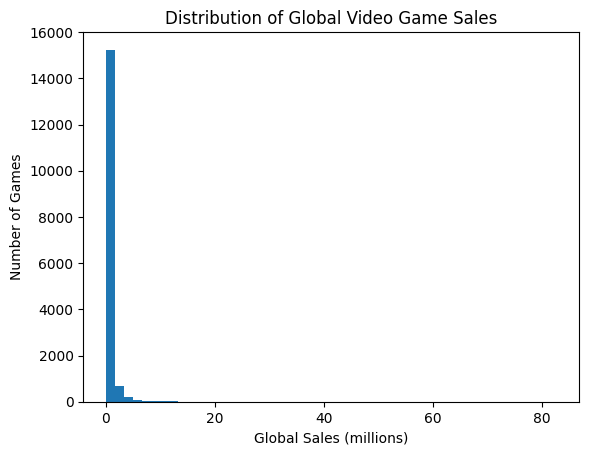

In [5]:
import matplotlib.pyplot as plt


#Distribution of Global Sales 


plt.hist(df['Global_Sales'], bins=50)
plt.xlabel("Global Sales (millions)")
plt.ylabel("Number of Games")
plt.title("Distribution of Global Video Game Sales")
plt.show()

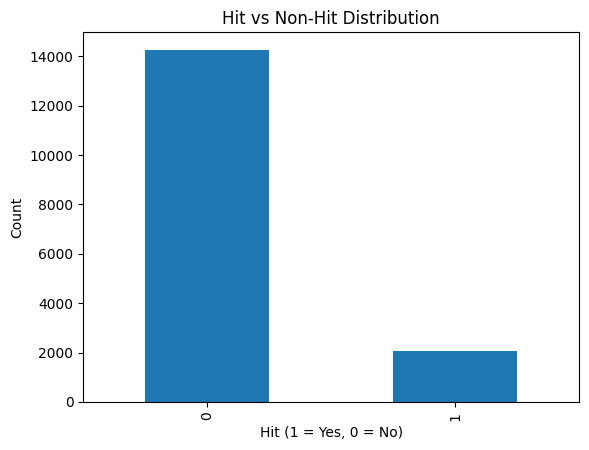

In [6]:
#Hit vs. non-Hit Count

df['Hit'].value_counts().plot(kind='bar')
plt.xlabel("Hit (1 = Yes, 0 = No)")
plt.ylabel("Count")
plt.title("Hit vs Non-Hit Distribution")
plt.show()

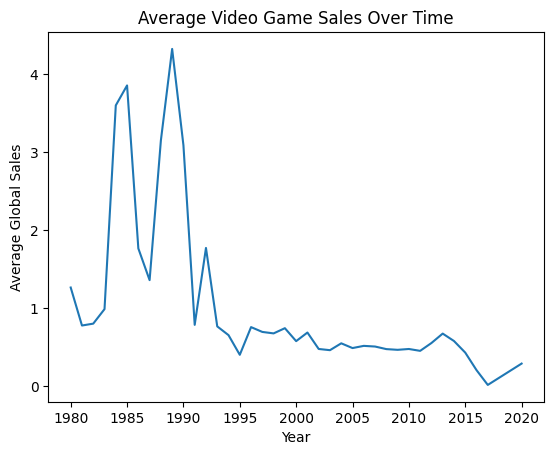

In [7]:
#Sales over Time 

sales_by_year = df.groupby('Year')['Global_Sales'].mean()

plt.plot(sales_by_year)
plt.xlabel("Year")
plt.ylabel("Average Global Sales")
plt.title("Average Video Game Sales Over Time")
plt.show()

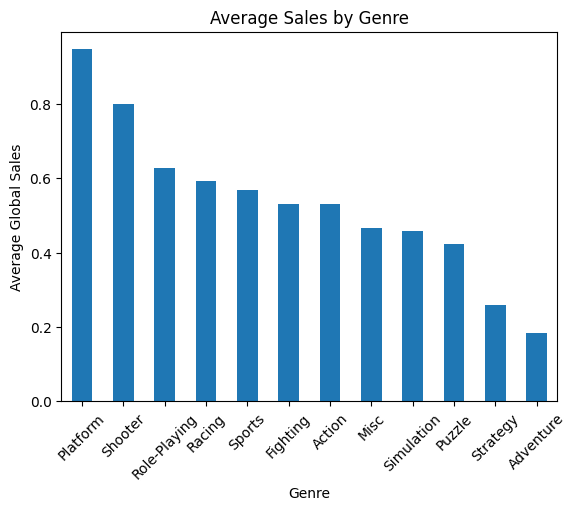

In [8]:
#Top Genres by Sales 

genre_sales = df.groupby('Genre')['Global_Sales'].mean().sort_values(ascending=False)

genre_sales.plot(kind='bar')
plt.xlabel("Genre")
plt.ylabel("Average Global Sales")
plt.title("Average Sales by Genre")
plt.xticks(rotation=45)
plt.show()

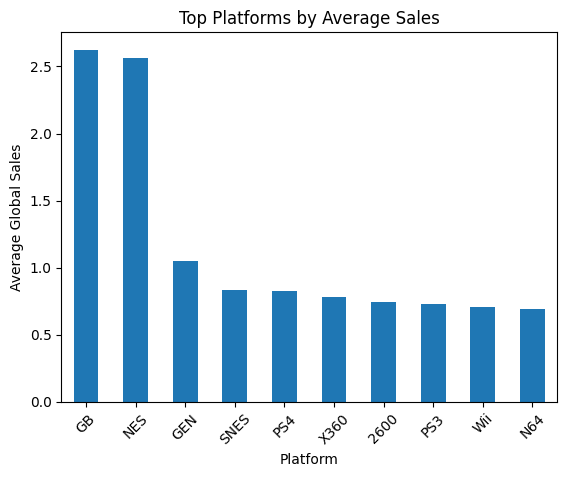

In [9]:
#Top Platforms 

platform_sales = df.groupby('Platform')['Global_Sales'].mean().sort_values(ascending=False)

platform_sales.head(10).plot(kind='bar')
plt.xlabel("Platform")
plt.ylabel("Average Global Sales")
plt.title("Top Platforms by Average Sales")
plt.xticks(rotation=45)
plt.show()

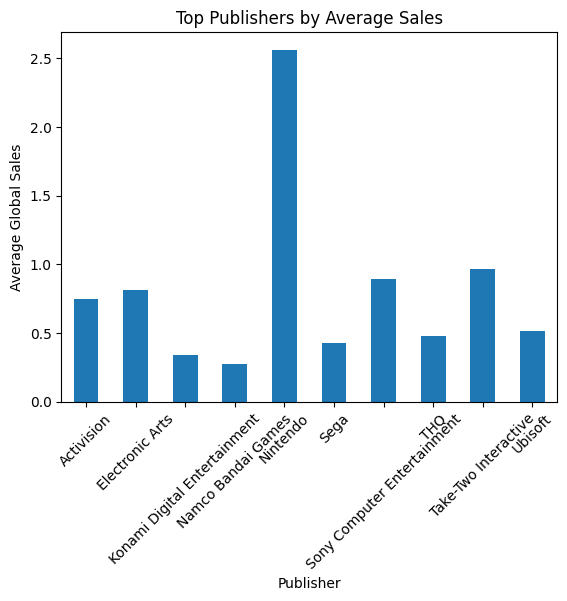

In [10]:
#Publisher Impact 

top_publishers = df['Publisher'].value_counts().head(10).index
publisher_sales = df[df['Publisher'].isin(top_publishers)]

publisher_sales.groupby('Publisher')['Global_Sales'].mean().plot(kind='bar')
plt.xlabel("Publisher")
plt.ylabel("Average Global Sales")
plt.title("Top Publishers by Average Sales")
plt.xticks(rotation=45)
plt.show()

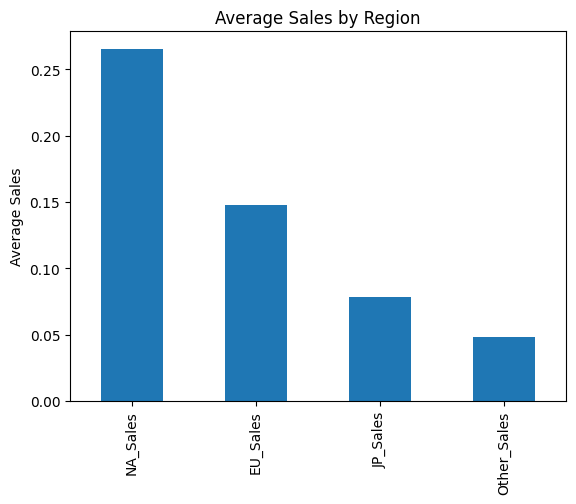

In [11]:
#Regional Differences 

region_sales = df[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].mean()

region_sales.plot(kind='bar')
plt.ylabel("Average Sales")
plt.title("Average Sales by Region")
plt.show()

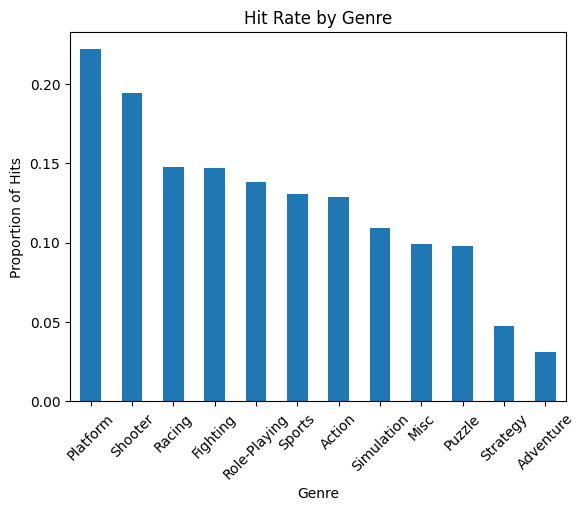

In [12]:
#Hit rate by Genre

hit_rate_genre = df.groupby('Genre')['Hit'].mean().sort_values(ascending=False)

hit_rate_genre.plot(kind='bar')
plt.title("Hit Rate by Genre")
plt.ylabel("Proportion of Hits")
plt.xticks(rotation=45)
plt.show()




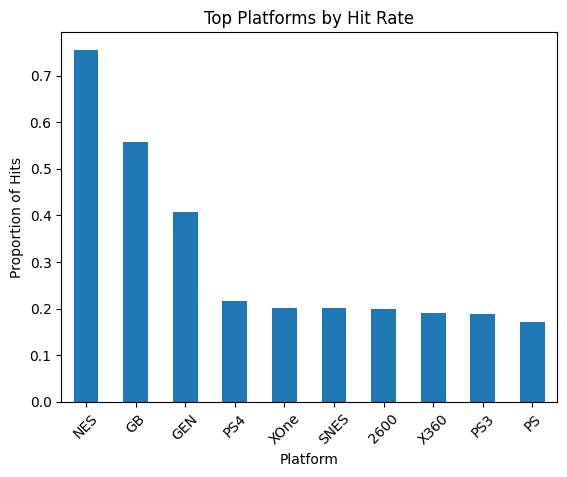

In [13]:
#Hit rate by Publisher 

hit_rate_platform = df.groupby('Platform')['Hit'].mean().sort_values(ascending=False)

hit_rate_platform.head(10).plot(kind='bar')
plt.title("Top Platforms by Hit Rate")
plt.ylabel("Proportion of Hits")
plt.xticks(rotation=45)
plt.show()

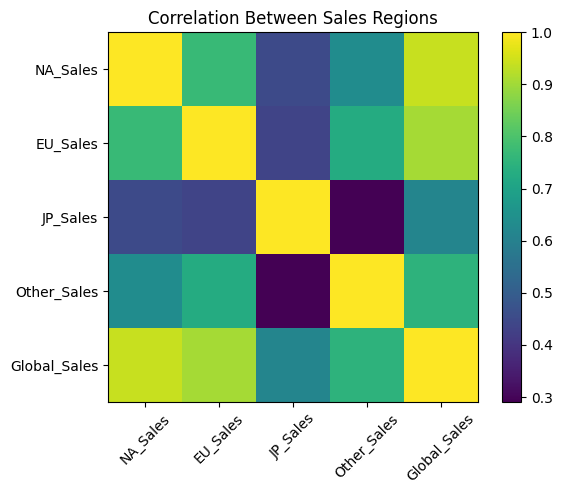

In [14]:
#Correlation Heatmap

corr = df[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']].corr()

plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Between Sales Regions")
plt.show()

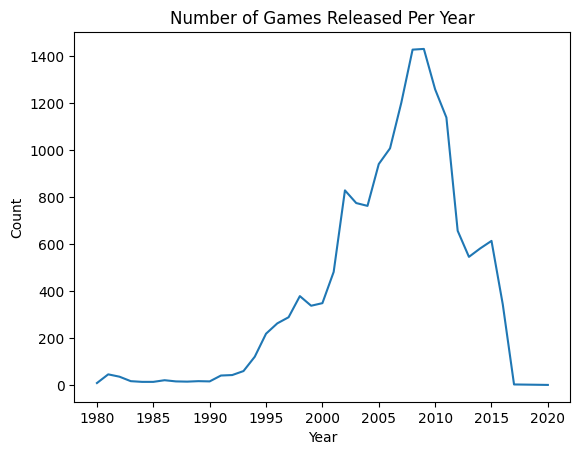

In [15]:
#Number of Games Realseed by Year


games_per_year = df['Year'].value_counts().sort_index()

plt.plot(games_per_year)
plt.title("Number of Games Released Per Year")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

---
## Week 3

### Games show up muiltiple times on platforms when applicable, but there isn't a Multi-Platform feature. I will create one

In [16]:
#Using One-Hot-Encoding for Categorical features 


#Create Multi-Platform Feature
# Count how many times each game appears
game_counts = df['Name'].value_counts()

# Map counts back to dataframe
df['MultiPlatformCount'] = df['Name'].map(game_counts)

# Convert to binary flag
df['MultiPlatformFlag'] = (df['MultiPlatformCount'] > 1).astype(int)




#Too many publishers, so have to limit them 
top_publishers = df['Publisher'].value_counts().head(10).index
df['Publisher'] = df['Publisher'].apply(lambda x: x if x in top_publishers else 'Other')


df_encoded = pd.get_dummies(df, columns=['Platform', 'Genre', 'Publisher'], drop_first=True)




#Drop Unecessray columns 
df_encoded = df_encoded.drop(['Name', 'Rank'], axis=1)
df_encoded = df_encoded.drop([
    'Global_Sales',
    'NA_Sales',
    'EU_Sales',
    'JP_Sales',
    'Other_Sales'
], axis=1)

## Now for Training/Testing for Logistic Regression

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix

X = df_encoded.drop('Hit', axis=1)
y = df_encoded['Hit']

# Remove all platform columns
X = X.drop([col for col in X.columns if 'Platform_' in col], axis=1)


#Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train_scaled, y_train)


y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))


print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7017758726270668
Precision: 0.2255358807082945
Recall: 0.6285714285714286
F1 Score: 0.3319615912208505

Confusion Matrix:
[[2050  831]
 [ 143  242]]


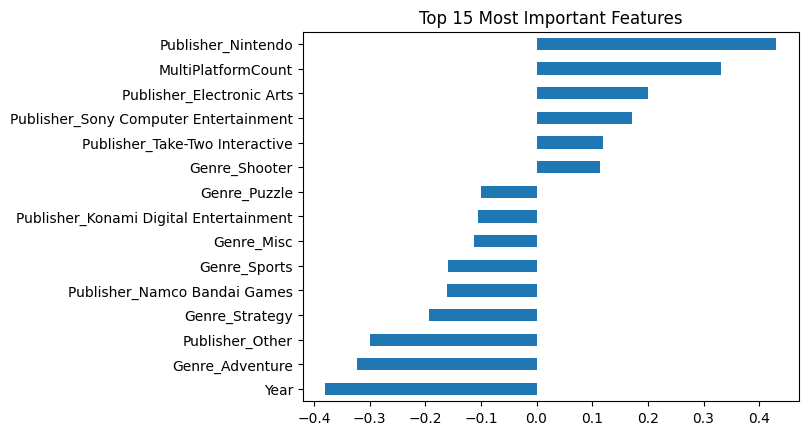

In [37]:
import pandas as pd
import matplotlib.pyplot as plt


importance = pd.Series(model.coef_[0], index=X.columns)

top_features = importance.abs().sort_values(ascending=False).head(15)

top_features = importance[top_features.index]  # keep signs

top_features.sort_values().plot(kind='barh')
plt.title("Top 15 Most Important Features")
plt.show()

“While multi-platform availability increases the likelihood of success, platform-specific effects remain significant, suggesting that both distribution strategy and console ecosystem independently contribute to game success.”

Platform features partially captured success, but a significant portion of that effect is explained by multi-platform availability and publisher influence.

“Games released on a greater number of platforms have a higher probability of success, indicating that market reach scales with platform coverage rather than simply benefiting from being multi-platform.”

The negative effect of release year is partially intertwined with platform generation effects, suggesting that both market saturation and console lifecycle influence game success.

---
## Next we move to Decision Tree 

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree




X = df_encoded.drop('Hit', axis=1)
y = df_encoded['Hit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)



tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)


y_pred = tree.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8600734843845683
Precision: 0.38819875776397517
Recall: 0.3246753246753247
F1 Score: 0.3536067892503536

Confusion Matrix:
[[2684  197]
 [ 260  125]]


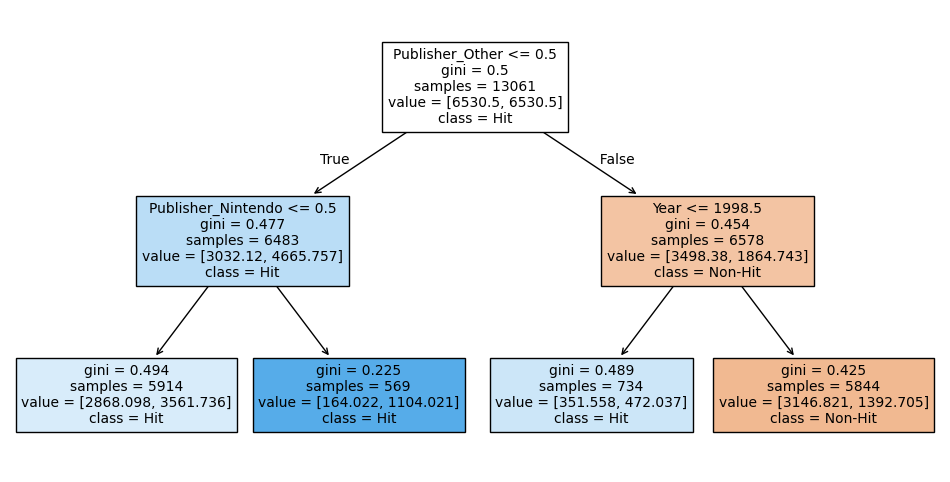

In [30]:
tree_simple = DecisionTreeClassifier(
    max_depth=2,
    min_samples_leaf=50,
    class_weight='balanced',
    random_state=42
)

tree_simple.fit(X_train, y_train)



plt.figure(figsize=(12,6))

plot_tree(
    tree_simple,
    feature_names=X.columns,
    class_names=["Non-Hit", "Hit"],
    filled=True,
    fontsize=10
)

plt.show()


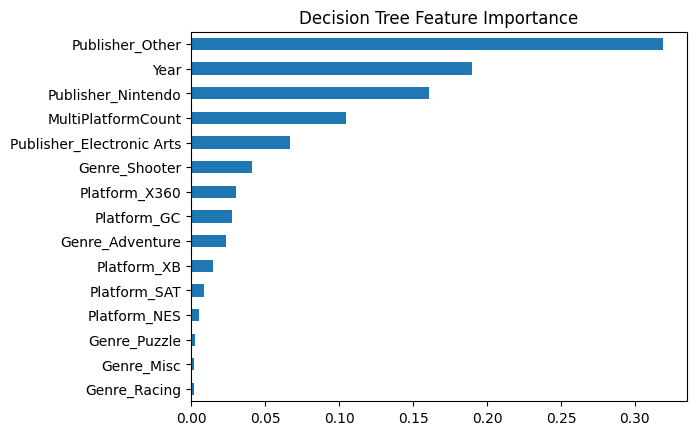

In [25]:
importance = pd.Series(tree.feature_importances_, index=X.columns)

top_features = importance.sort_values(ascending=False).head(15)

top_features.sort_values().plot(kind='barh')
plt.title("Decision Tree Feature Importance")
plt.show()

The most important factor in predicting game success is whether the game is published by a major publisher. Among major publishers, Nintendo stands out as a unique case, reflecting its strong ecosystem of exclusive titles. For smaller publishers, success is strongly influenced by release year, with older games having a higher likelihood of becoming hits.